# Self-map test: real quantum magnetometer data, end to end (COH-28)

This is a real QuSpin QTFM flight, flown on a drone in Ontario on 14 March 2026. There's no Tellus map
there, so we **make a map from every other survey line and navigate along the lines in between**,
which the map has never seen. The magnetometer, its noise, the drone's own field and the heading
error are all real. Only the INS drift is simulated, because this log's IMU axes are unknown.
Edit the settings in a cell and re-run it.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from navfilter import ParticleFilter, PFConfig, selfmap

CSV = "../data/QuSpin/dynamic_csv/T2M0-00QK_Data7_flat_interpolation_Quspin_Dynamic.csv"
log = selfmap.load_survey(CSV)
print(f"{log.t[-1] / 60:.0f} min at 10 Hz, {log.line.max() + 1} survey lines found")

31 min at 10 Hz, 9 survey lines found


## 1. The flight and its lines

Lines are numbered south to north. **Even** lines (westbound) become the map, and **odd** lines
(eastbound) are the test.

anomaly along the lines varies by 8.6 nT (std), 48 nT end to end


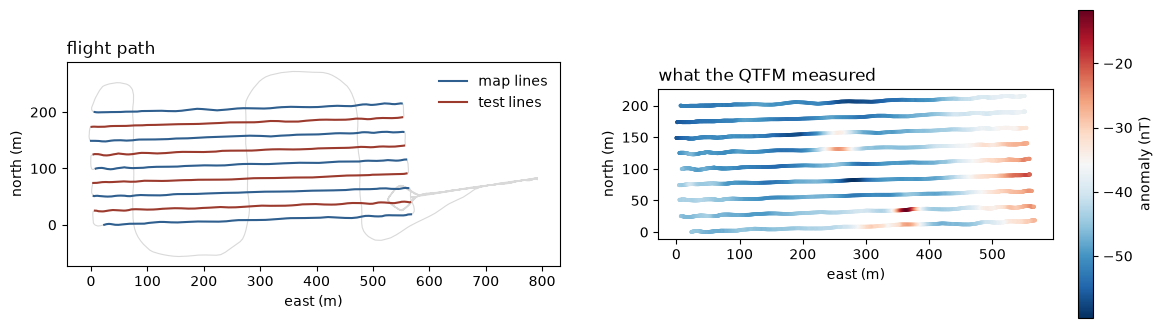

In [2]:
MAP_LINES = log.line % 2 == 0        # try: log.line % 3 != 1   (a denser map)
MAP_LINES &= log.line >= 0
TEST_LINES = (log.line >= 0) & ~MAP_LINES

# local metres east/north of the survey's south-west corner, for drawing
from ins.types import metres_per_degree
m_lat, m_lon = metres_per_degree(log.lat.mean())
on = log.line >= 0
east = (log.lon - log.lon[on].min()) * m_lon
north = (log.lat - log.lat[on].min()) * m_lat

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(east, north, color="0.85", lw=0.8)
ax[0].plot(np.where(MAP_LINES, east, np.nan), north, color="#2f5f8f", label="map lines")
ax[0].plot(np.where(TEST_LINES, east, np.nan), north, color="#9c3a2e", label="test lines")
ax[0].set_title("flight path", loc="left"); ax[0].legend(frameon=False)
sc = ax[1].scatter(east[on], north[on], c=log.anomaly_nt[on], s=3, cmap="RdBu_r")
fig.colorbar(sc, ax=ax[1], label="anomaly (nT)"); ax[1].set_title("what the QTFM measured", loc="left")
for a in ax: a.set_aspect("equal"); a.set_xlabel("east (m)"); a.set_ylabel("north (m)")
print(f"anomaly along the lines varies by {log.anomaly_nt[on].std():.1f} nT (std), {np.ptp(log.anomaly_nt[on]):.0f} nT end to end")

## 2. The map, and how well it predicts lines it never saw

The residual is what the filter has to contend with. Its **mean** is the heading effect (the map was
flown one way, the test lines the other), and its **spread** is everything else.

test lines vs map: mean +1.2 nT, spread 3.3 nT, 5% off the map


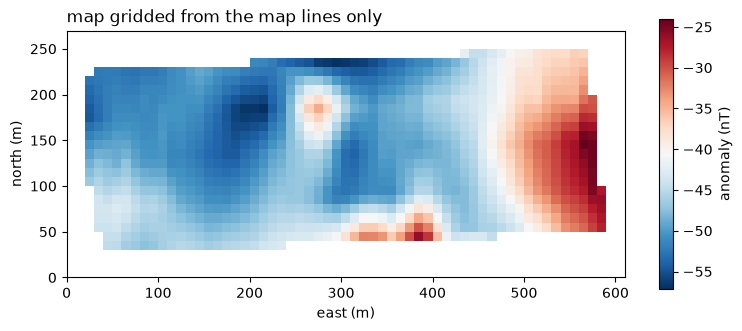

In [3]:
smap = selfmap.grid_lines(log, MAP_LINES, cell_m=10)

pred = smap.sample_track(log.lat[TEST_LINES], log.lon[TEST_LINES])
resid = log.anomaly_nt[TEST_LINES] - pred
print(f"test lines vs map: mean {np.nanmean(resid):+.1f} nT, spread {np.nanstd(resid):.1f} nT, "
      f"{np.isnan(pred).mean():.0%} off the map")

l, b, r, t = smap.bounds
plt.figure(figsize=(9, 3.5))
plt.imshow(smap.values, extent=(0, r - l, 0, t - b), cmap="RdBu_r")    # metres from the map corner
plt.colorbar(label="anomaly (nT)"); plt.title("map gridded from the map lines only", loc="left")
plt.xlabel("east (m)"); plt.ylabel("north (m)");

## 3. Navigate the test lines

GNSS is cut at the start of the survey. The INS track is the **real GPS path plus a simulated INS's
drift**, and the filter only gets magnetometer readings from the test lines. Readings from map lines are
hidden from it, because they built the map. Each seed is a different INS error.

In [4]:
GRADE = "tactical"                 # or "consumer_mems", "navigation"
SEEDS = range(5)

window = log.window(0, log.line.max())
truth = log.trajectory(window)
z = np.where(TEST_LINES[window], log.field_nt[window], np.nan)
core = log.core_fn()

rows, runs = [], []
for seed in SEEDS:
    ins = selfmap.drifted_ins(log, window, GRADE, seed=seed)
    anomaly = z - core(ins.lat, ins.lon, ins.alt_m)        # IGRF at the INS position, as in flight
    run = ParticleFilter(smap, PFConfig(grade=GRADE, seed=seed)).run(
        ins, truth.t, anomaly, truth=truth, core_fn=core, name=f"seed {seed}")
    runs.append(run)
    rows.append(dict(seed=seed,
                     ins_final_m=run.ins_error_m[-1], filter_final_m=run.error_m[-1],
                     ins_rms_m=np.sqrt(np.nanmean(run.ins_error_m**2)),
                     filter_rms_m=np.sqrt(np.nanmean(run.error_m**2))))
results = pd.DataFrame(rows).set_index("seed").round(0)
print(f"{GRADE}, {(truth.t[-1] - truth.t[0]) / 60:.0f} min after the GNSS cut")
results

tactical, 11 min after the GNSS cut


,ins_final_m,filter_final_m,ins_rms_m,filter_rms_m
seed,,,,
0,350.0,37.0,162.0,35.0
1,908.0,71.0,438.0,46.0
2,1596.0,31.0,787.0,45.0
3,599.0,174.0,363.0,101.0
4,654.0,33.0,285.0,38.0


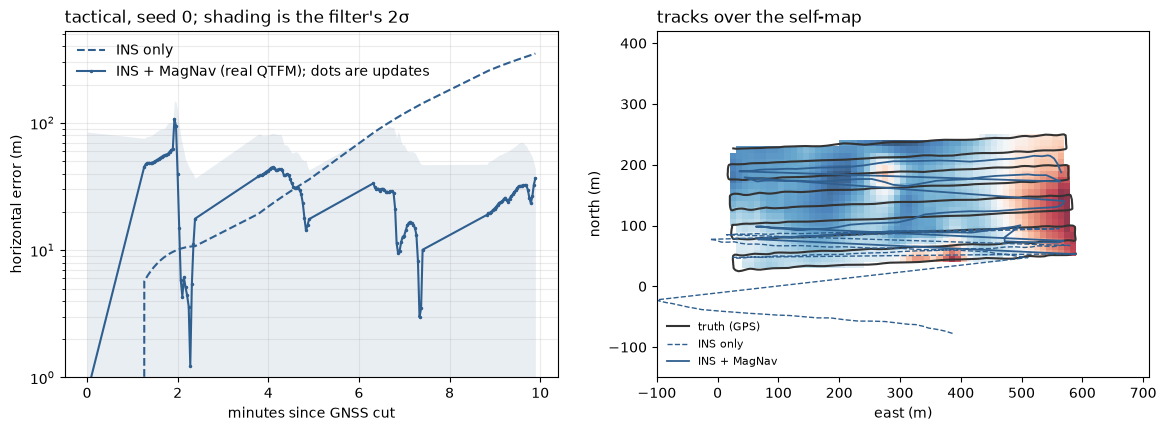

In [5]:
SHOW = 0                                   # which seed to draw
run = runs[SHOW]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
el = run.elapsed_s / 60
ax[0].plot(el, run.ins_error_m, "--", color="#2f5f8f", label="INS only")
ax[0].plot(el, run.error_m, ".-", ms=3, color="#2f5f8f", label="INS + MagNav (real QTFM); dots are updates")
ax[0].fill_between(el, 0.1, run.sigma2_m, color="#2f5f8f", alpha=0.1, lw=0)
ax[0].set_yscale("log"); ax[0].set_ylim(1, None); ax[0].grid(alpha=0.25, which="both")
ax[0].set_xlabel("minutes since GNSS cut"); ax[0].set_ylabel("horizontal error (m)")
ax[0].set_title(f"{GRADE}, seed {SHOW}; shading is the filter's 2σ", loc="left"); ax[0].legend(frameon=False)

def to(lon, lat):                          # metres from the map corner
    x, y = smap._to_grid.transform(lon, lat)
    return np.asarray(x) - l, np.asarray(y) - b
ax[1].imshow(smap.values, extent=(0, r - l, 0, t - b), cmap="RdBu_r", alpha=0.8)
ax[1].plot(*to(truth.lon, truth.lat), color="0.2", lw=1.5, label="truth (GPS)")
ax[1].plot(*to(run.ins_track.lon, run.ins_track.lat), "--", color="#2f5f8f", lw=1, label="INS only")
ax[1].plot(*to(run.estimate.lon, run.estimate.lat), color="#2f5f8f", lw=1.3, label="INS + MagNav")
ax[1].set_xlim(-100, r - l + 100); ax[1].set_ylim(-150, t - b + 150); ax[1].set_aspect("equal")
ax[1].set_xlabel("east (m)"); ax[1].set_ylabel("north (m)")
ax[1].legend(frameon=False, fontsize=8, loc="lower left"); ax[1].set_title("tracks over the self-map", loc="left");

**What this does and doesn't show.** The magnetic side is fully real: sensor, platform noise,
heading effect, and a map that never saw the test lines. The INS drift is simulated, and the area is small
(550 × 200 m), so the filter has little room to get lost. That makes this a check that *real QTFM data is
good enough to match*, not a long-range navigation result.